# County unemployment early warning: support vector machines, compared with logistic regression

**Same question as notebook 01:** for a county in month *t*, will its unemployment rate rise by **≥ 0.5 percentage points over
the next 3 months** (`y_label` in `marts.county_month`)?

This notebook rebuilds **exactly the same data** as notebook 01 (same features, same out-of-time test year, same 3-month gap, same
stratified 60k tuning subsample, same `StratifiedGroupKFold` by quarter), then asks whether a **support vector machine** does better.

## Where we are coming from: what logistic regression taught us (notebook 01)

| Finding from LR | Number (test year 2025-04 to 2026-05) | What it means for SVM |
|---|---|---|
| L1 / L2 / elastic net are equivalent | test ROC AUC 0.7985–0.7991 for all penalties, all at C = 0.1 | With only 26 features, regularization isn't the bottleneck. A **linear** SVM probably ties LR; any gain has to come from **nonlinearity** (kernels). |
| The **seasonal-naive rule beats LR** on hard decisions | rule F1 0.667 vs LR F1 0.59 | The features miss *county-specific* seasonality. A kernel *might* learn county × season interactions; adding the seasonal feature directly is the more direct fix. Both are tested (§7). |
| CV is optimistic | CV ROC AUC 0.842 → test 0.799 | Trust the out-of-time test year, not CV. |
| Training **without 2020–21** helps | test ROC AUC 0.799 → 0.827 | Tested again for SVM (§7). |
| F1-optimal threshold ≈ 0.30, not 0.5 | | SVM thresholds are also chosen on held-out *training* data, never on test. |
| PCA truncation and UMAP hurt | PCA-11 AUC 0.65; UMAP AUC 0.41 | No dimensionality reduction here. SVM gets the 26 standardized features. |

**Carried-over caveats.** The test year is one economic regime. Training labels are *revised* LAUS history while real-time use would see *preliminary* data.
County rates aren't seasonally adjusted. October 2025 has no county rate in LAUS (it looks like the BLS gap from the federal shutdown), so October and July 2025 have no label.
Nothing is saved from this notebook; notebook 03 (`03_final_model.ipynb`) makes the final choice.

## What's different about SVMs

An SVM finds the boundary with the **largest margin** between the classes, and it minimizes the **hinge loss**
$\max(0,\,1 - y_i f(x_i))$ (with $y_i \in \{-1,+1\}$) instead of the log loss LR uses. Points beyond the margin cost nothing; only the
points on or inside the margin, the **support vectors**, define the boundary. Consequences that shape this notebook:
1. **Kernels.** The RBF kernel lets the boundary curve. This is the main reason to try SVM after LR.
2. **No probabilities.** SVM outputs a *distance to the boundary* (`decision_function`), not a probability. To report log loss,
   calibration, and a meaningful threshold, we **calibrate** with Platt scaling (§3).
3. **Scaling.** Exact kernel SVM training costs roughly $O(n^2)$ to $O(n^3)$ in the number of rows. It can't use all 377k rows; §5 explains why.
   So we use a **linear SVM** on the full data and **kernel SVMs** (RBF, polynomial, sigmoid) on subsamples, and compare the kernels.

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.frozen import FrozenEstimator
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_val_predict, train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, brier_score_loss, hinge_loss,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, precision_recall_curve)
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.4f}".format)
RNG = 42

## 1. Same data as notebook 01

The cells below repeat notebook 01's loading, seasonal-naive baseline, train/test split, and tuning subsample **with the same seeds**,
so every row lands in the same set. An assert checks that the split matches notebook 01's numbers.

In [2]:
if os.environ.get("MOTHERDUCK_TOKEN"):
    con = duckdb.connect("md:unemployment")
    df = con.sql("select * from marts.county_month order by county_fips, month").df()
    con.close()
    source = "MotherDuck: unemployment.marts.county_month"
else:
    df = pd.read_parquet("data/county_month.parquet").sort_values(["county_fips", "month"])
    source = "data/county_month.parquet"
df["month"] = pd.to_datetime(df["month"])
FEATURES = [c for c in df.columns if c.startswith("f_")]

# seasonal-naive score: the county's change over the same 3-month window last year (backward-looking only)
df["m_idx"] = df.month.dt.year * 12 + df.month.dt.month
key = df[["county_fips", "m_idx", "f_rate"]]
n_before = len(df)
for lag in [9, 12, 21, 24]:
    df = df.merge(key.assign(m_idx=key.m_idx + lag).rename(columns={"f_rate": f"rate_tm{lag}"}), on=["county_fips", "m_idx"], how="left")
assert len(df) == n_before, "merge changed the row count"
df["seasonal_naive_delta"] = df.rate_tm9 - df.rate_tm12

lab = df[df["is_labeled"]].copy(); lab["y"] = lab["y_label"].astype(int)
lab_months = np.sort(lab.month.unique())
test_start, gap_start = lab_months[-12], lab_months[-15]
train = lab[lab.month < gap_start].copy()
test = lab[lab.month >= test_start].copy()

X_cols = FEATURES
tune, _ = train_test_split(train, train_size=60_000, stratify=train.y, random_state=RNG)
X_tune, y_tune = tune[X_cols], tune.y.values
groups_tune = (tune.month.dt.year * 10 + tune.month.dt.quarter).values
X_train, y_train = train[X_cols], train.y.values
X_test, y_test = test[X_cols], test.y.values
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RNG)

print(f"source: {source}")
print(f"train {len(train):,} rows ({train.month.min():%Y-%m} to {train.month.max():%Y-%m}), positive rate {y_train.mean():.3f}")
print(f"test  {len(test):,} rows ({test.month.min():%Y-%m} to {test.month.max():%Y-%m}), positive rate {y_test.mean():.3f}")
print(f"tune  {len(tune):,} rows, positive rate {y_tune.mean():.3f}")
assert len(train) == 377_097 and len(test) == 37_716, "split differs from notebook 01 (data changed?)"

source: MotherDuck: unemployment.marts.county_month
train 377,097 rows (2015-01 to 2024-12), positive rate 0.273
test  37,716 rows (2025-04 to 2026-05), positive rate 0.288
tune  60,000 rows, positive rate 0.273


### 1.0 Why the tuning sample overlaps the training set (same reasoning as notebook 01, §3.1)

`tune` is a 60k sample drawn *from* `train`, so the SVMs are tuned on rows that also end up in the training data. Keeping a separate
tuning set (deleting those 60k rows from `train`) was considered and rejected:

1. **The tuning sample exists for speed.** SVM grid searches are expensive (§5), so CV runs on a sample. Inside it, each fold fits on
   4/5 and scores the held-out 1/5, so every tuning score comes from rows that fold's model didn't see.
2. **The overlap isn't leakage.** The reported numbers come from the test year, which is in neither `tune` nor `train`.
3. **Separate rows wouldn't mean separate information.** The same county in neighboring months has nearly identical features and
   overlapping 3-month targets, and all counties in a month share the same FRED values. Deleting tuning rows from `train` would still leave
   their near-copies behind, and it would cost about 16% of the training data.
4. **The real weakness is time.** CV folds are grouped by quarter but still mix years, so settings are graded on regimes the model has
   seen. This flatters flexible models most, and it shows up below: kernels beat linear models in CV (RBF 0.860, polynomial 0.861 vs. LR
   0.842) and lose to them on the test year (RBF 0.784, polynomial 0.774 vs. LR 0.799). Removing tuning rows from training would not
   change that. Only an out-of-time tuning period would.
5. **Fold spread understates real uncertainty.** The five folds come from the same years, so their sd is sampling noise, not
   year-to-year variation.

**Where this notebook already uses time correctly.** SVM probabilities and thresholds come from the **calibration year** (§1.1), the
last 12 training months, after a 3-month gap from the SVM fit set. That is an out-of-time holdout. One small overlap remains: the tuning
sample is drawn from all training years, so some calibration-year rows also helped pick hyperparameters. That can make the calibration-year
threshold slightly optimistic, but it never touches the test year.

**Bottom line.** The overlap is standard and safe. The out-of-time **test year** is the number to trust, and the CV-vs-test gaps
below are the clearest sign of what CV inside the training years can and can't tell you.

### 1.1 One extra split for SVM: a calibration year

SVMs need a held-out set to (a) **turn decision scores into probabilities** (Platt scaling) and (b) **choose the decision threshold**.
That set must not be the test year, and it shouldn't be rows the SVM was trained on (the scores on training rows are over-confident).

We use the time-respecting version of notebook 01's design, *inside* the training period:
- **calibration year** = the last 12 training months,
- a **3-month gap** before it (so no target window overlaps),
- **SVM fit set** = everything earlier.

Logistic regression from notebook 01 keeps its original setup (fit on all of `train`, threshold from out-of-fold CV) so its numbers
reproduce. Both approaches choose the threshold without touching the test year.

In [3]:
train_months = np.sort(train.month.unique())
cal_start, fit_end = train_months[-12], train_months[-15]
fit = train[train.month < fit_end]
cal = train[train.month >= cal_start]
X_fit, y_fit = fit[X_cols], fit.y.values
X_cal, y_cal = cal[X_cols], cal.y.values
pd.DataFrame({"rows": [len(fit), len(cal), len(test)],
              "from": [fit.month.min(), cal.month.min(), test.month.min()],
              "to": [fit.month.max(), cal.month.max(), test.month.max()],
              "positive_rate": [y_fit.mean(), y_cal.mean(), y_test.mean()]},
             index=["SVM fit set", "calibration year", "test year"])

,rows,from,to,positive_rate
SVM fit set,329952,2015-01-01,2023-09-01,0.2600
calibration year,37716,2024-01-01,2024-12-01,0.3100
test year,37716,2025-04-01,2026-05-01,0.2884


## 2. The logistic regression benchmark, reproduced

Notebook 01's CV picked **elastic net ρ = 0.25, C = 0.1** by log loss (all penalties tied within noise). We refit it on all training rows
and recompute its out-of-fold F1 threshold. This is the bar every SVM has to clear.

In [4]:
def make_lr(C=0.1, l1_ratio=0.25):
    return Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                     ("lr", LogisticRegression(C=C, l1_ratio=l1_ratio, solver="saga", max_iter=3000, tol=1e-3, random_state=RNG))])

def f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[np.argmax(f1s)]), float(f1s.max())

def evaluate(name, y_true, p=None, yhat=None, thr=None, dec=None, fit_s=np.nan):
    if yhat is None:
        yhat = (p >= thr).astype(int)
    has_p = p is not None
    return {"model": name, "threshold": thr,
            "log_loss": log_loss(y_true, p) if has_p else np.nan,
            "brier": brier_score_loss(y_true, p) if has_p else np.nan,
            "roc_auc": roc_auc_score(y_true, p) if has_p else np.nan,
            "pr_auc": average_precision_score(y_true, p) if has_p else np.nan,
            "hinge": hinge_loss(y_true, dec) if dec is not None else np.nan,
            "accuracy": accuracy_score(y_true, yhat), "precision": precision_score(y_true, yhat, zero_division=0),
            "recall": recall_score(y_true, yhat), "f1": f1_score(y_true, yhat), "fit_seconds": fit_s}

rows, probs, timing = [], {}, {}

p_dummy = DummyClassifier(strategy="prior").fit(X_train, y_train).predict_proba(X_test)[:, 1]
rows.append(evaluate("Dummy (prior)", y_test, p_dummy, thr=0.5))
rows.append(evaluate("Seasonal-naive rule", y_test, yhat=(test.seasonal_naive_delta.fillna(0).values >= 0.5).astype(int)))

t0 = time.time()
oof_lr = cross_val_predict(make_lr(), X_tune, y_tune, cv=cv, groups=groups_tune, method="predict_proba", n_jobs=-1)[:, 1]
THR_LR, _ = f1_threshold(y_tune, oof_lr)
t0 = time.time(); lr = make_lr().fit(X_train, y_train); t_lr = time.time() - t0
probs["LR (EN ρ=0.25, C=0.1)"] = lr.predict_proba(X_test)[:, 1]
rows.append(evaluate("LR (EN ρ=0.25, C=0.1)", y_test, probs["LR (EN ρ=0.25, C=0.1)"], thr=THR_LR, fit_s=t_lr))
print(f"LR threshold (OOF F1-optimal): {THR_LR:.3f}; LR fit on {len(X_train):,} rows in {t_lr:.0f}s")
pd.DataFrame(rows).set_index("model")

LR threshold (OOF F1-optimal): 0.297; LR fit on 377,097 rows in 58s


,threshold,log_loss,brier,roc_auc,pr_auc,hinge,accuracy,precision,recall,f1,fit_seconds
model,,,,,,,,,,,
Dummy (prior),0.5000,0.6013,0.2055,0.5000,0.2884,NaN,0.7116,0.0000,0.0000,0.0000,NaN
Seasonal-naive rule,NaN,NaN,NaN,NaN,NaN,NaN,0.7940,0.6247,0.7156,0.6671,NaN
"LR (EN ρ=0.25, C=0.1)",0.2969,0.4977,0.1631,0.7986,0.6432,NaN,0.7660,0.5958,0.5862,0.5909,57.8798


## 3. Turning SVM scores into probabilities (Platt scaling)

`decision_function` returns a signed distance: > 0 means the positive side of the boundary, and the margin edges are at ±1. Its scale
is arbitrary, so it can't be read as a probability, and log loss, Brier score, and calibration plots need probabilities.

**Platt scaling** fits a one-feature logistic regression $P(y=1) = \sigma(a\,f(x) + b)$ on held-out scores. Here that's the
calibration year, with the fitted SVM frozen (`FrozenEstimator`) so only $a, b$ are learned. Because the sigmoid is monotone,
**ROC AUC and PR AUC don't change**. Only log loss, Brier score, and calibration do.

The helper below does the whole SVM recipe the same way for every variant: fit on the fit set, calibrate on the calibration year,
choose the F1 threshold on the calibration year, and score the test year.

In [5]:
fitted = {}

def fit_calibrate_score(name, model, X_f, y_f):
    t0 = time.time(); model.fit(X_f, y_f); t_fit = time.time() - t0
    platt = CalibratedClassifierCV(FrozenEstimator(model), method="sigmoid").fit(X_cal, y_cal)
    thr, _ = f1_threshold(y_cal, platt.predict_proba(X_cal)[:, 1])
    p = platt.predict_proba(X_test)[:, 1]
    dec = model.decision_function(X_test)
    fitted[name] = {"model": model, "platt": platt, "thr": thr, "dec_test": dec}
    probs[name] = p
    rows.append(evaluate(name, y_test, p, thr=thr, dec=dec, fit_s=t_fit))
    print(f"{name}: fit {t_fit:.0f}s on {len(X_f):,} rows, threshold {thr:.3f}, test ROC AUC {roc_auc_score(y_test, p):.4f}")
    return rows[-1]

## 4. Linear SVM

A linear SVM has the same kind of boundary as LR (a hyperplane) but a different loss. Tuned hyperparameters:

| Hyperparameter | Values | Meaning |
|---|---|---|
| `C` | 10⁻⁴ … 10 | Inverse regularization, as in LR. Small C means a wide margin and many margin violations allowed. |
| `penalty` | L2, L1 | Same idea as LR: L1 zeros out coefficients. |
| `loss` | hinge, squared hinge | Squared hinge penalizes violations quadratically (smoother; required with L1). |
| `class_weight` | none, balanced | "Balanced" up-weights the 27% positive class so violations on positives cost about 2.7× more. |

**Tuning metric.** Without probabilities there's no log loss during CV, so we tune on **ROC AUC** (threshold-free; uses
`decision_function`) and also track PR AUC, F1, and accuracy. F1 and accuracy here use the SVM's built-in cutoff (decision = 0), which
is why they're only indicative. Same tuning rows, folds, and quarter groups as LR.

180 fits in 797s; best: {'svm__C': np.float64(10.0), 'svm__class_weight': 'balanced', 'svm__loss': 'hinge', 'svm__penalty': 'l2'}, CV ROC AUC 0.8430


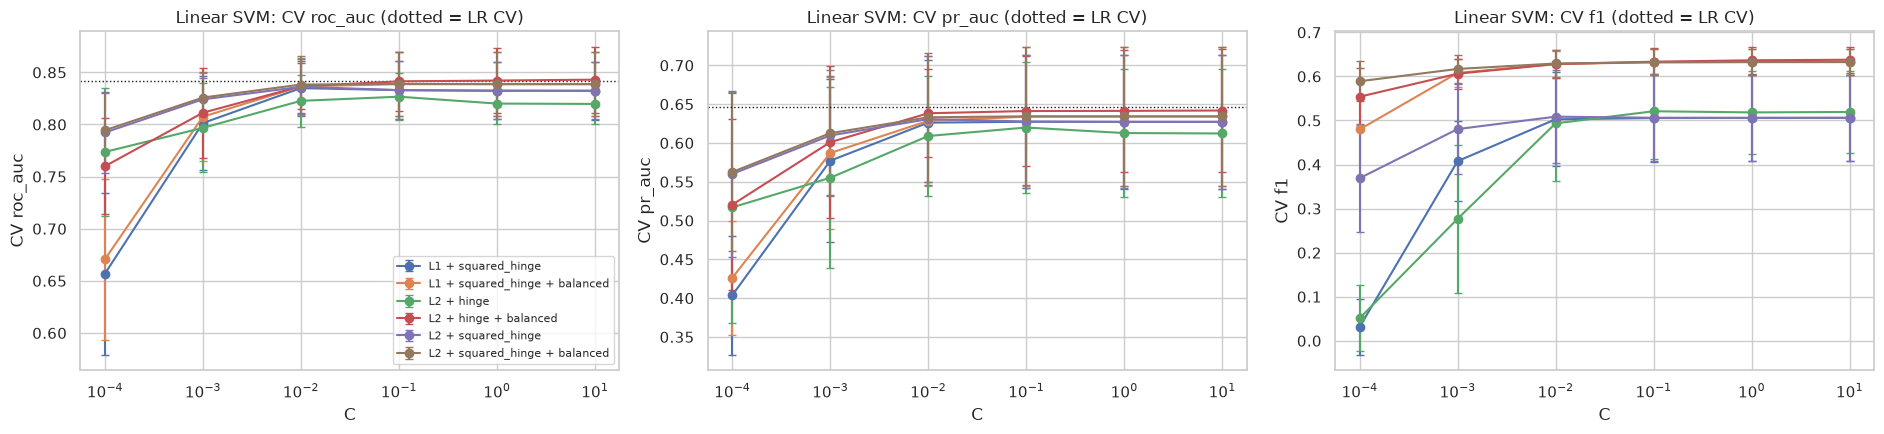

,variant,C,mean_test_roc_auc,std_test_roc_auc,mean_test_pr_auc,mean_test_f1,mean_test_accuracy
23,L2 + hinge + balanced,10.0000,0.8430,0.0316,0.6418,0.6378,0.7442
14,L2 + squared_hinge + balanced,0.1000,0.8388,0.0305,0.6343,0.6321,0.7430
31,L1 + squared_hinge + balanced,0.1000,0.8387,0.0307,0.6338,0.6321,0.7428
8,L2 + squared_hinge,0.0100,0.8361,0.0265,0.6307,0.5087,0.7805
28,L1 + squared_hinge,0.0100,0.8349,0.0265,0.6262,0.5026,0.7776
13,L2 + hinge,0.1000,0.8266,0.0223,0.6199,0.5209,0.7825


In [6]:
def make_linsvm(**kw):
    return Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                     ("svm", LinearSVC(dual="auto", max_iter=20_000, random_state=RNG, **kw))])

Cs = np.logspace(-4, 1, 6)
lin_grid = [
    {"svm__penalty": ["l2"], "svm__loss": ["squared_hinge", "hinge"], "svm__C": Cs, "svm__class_weight": [None, "balanced"]},
    {"svm__penalty": ["l1"], "svm__loss": ["squared_hinge"], "svm__C": Cs, "svm__class_weight": [None, "balanced"]},
]
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1", "accuracy": "accuracy"}
t0 = time.time()
lin_search = GridSearchCV(make_linsvm(), lin_grid, scoring=scoring, refit="roc_auc", cv=cv, n_jobs=-1).fit(X_tune, y_tune, groups=groups_tune)
print(f"{len(lin_search.cv_results_['params']) * 5} fits in {time.time() - t0:.0f}s; best: {lin_search.best_params_}, CV ROC AUC {lin_search.best_score_:.4f}")

lr_cv = pd.DataFrame(lin_search.cv_results_)
lr_cv["C"] = lr_cv.param_svm__C.astype(float)
lr_cv["variant"] = (lr_cv.param_svm__penalty.astype(str).str.upper() + " + " + lr_cv.param_svm__loss.astype(str)
                    + lr_cv.param_svm__class_weight.map(lambda v: " + balanced" if v == "balanced" else ""))
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
for ax, m in zip(axes, ["roc_auc", "pr_auc", "f1"]):
    for v, g in lr_cv.groupby("variant"):
        ax.errorbar(g.C, g[f"mean_test_{m}"], yerr=g[f"std_test_{m}"], marker="o", capsize=3, label=v)
    if m in ("roc_auc", "pr_auc"):
        ax.axhline({"roc_auc": 0.842, "pr_auc": 0.646}[m], color="k", ls=":", lw=1)
    ax.set_xscale("log"); ax.set_xlabel("C"); ax.set_ylabel(f"CV {m}"); ax.set_title(f"Linear SVM: CV {m} (dotted = LR CV)")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()
lr_cv.loc[lr_cv.groupby("variant").mean_test_roc_auc.idxmax(), ["variant", "C", "mean_test_roc_auc", "std_test_roc_auc", "mean_test_pr_auc", "mean_test_f1", "mean_test_accuracy"]].sort_values("mean_test_roc_auc", ascending=False)

**Reading this.** As with LR, the curves flatten once C is large enough, and the variants converge. **`class_weight="balanced"` moves ROC AUC
only a little** (+0.003 to +0.016 here; it shifts the boundary more than it changes the ranking). Its bigger effect is to **raise F1 at the default cutoff**,
because unweighted SVMs put the boundary where few positives are predicted. Since we choose a threshold after calibration anyway,
the ranking metrics are what matter.

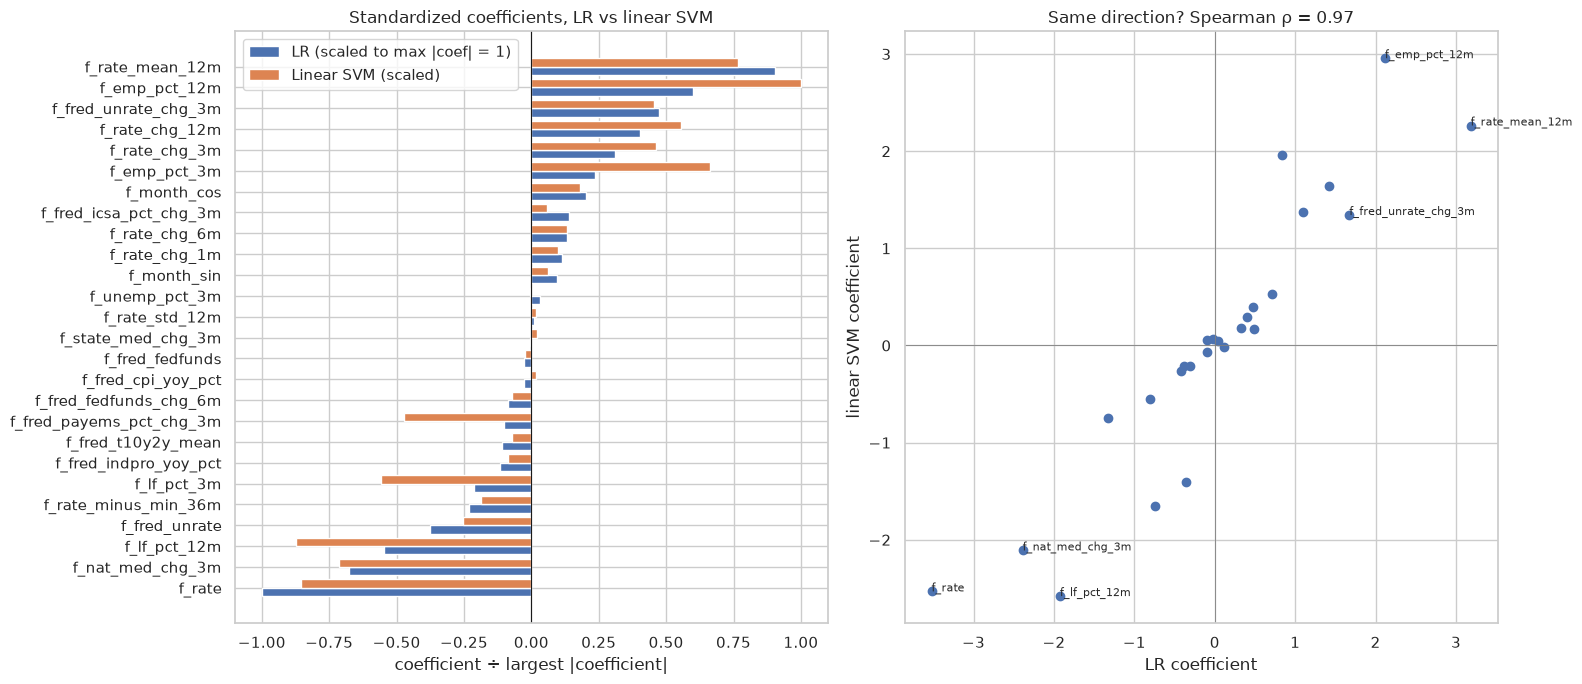

In [7]:
best_lin = lin_search.best_estimator_
lin_coef = pd.Series(best_lin.named_steps["svm"].coef_.ravel(), index=X_cols)
lr_coef = pd.Series(lr.named_steps["lr"].coef_.ravel(), index=X_cols)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
order = lr_coef.sort_values().index
axes[0].barh(np.arange(len(order)) - 0.2, lr_coef[order] / lr_coef.abs().max(), height=0.4, label="LR (scaled to max |coef| = 1)")
axes[0].barh(np.arange(len(order)) + 0.2, lin_coef[order] / lin_coef.abs().max(), height=0.4, label="Linear SVM (scaled)")
axes[0].set_yticks(np.arange(len(order))); axes[0].set_yticklabels(order); axes[0].axvline(0, color="k", lw=0.8)
axes[0].legend(); axes[0].set_title("Standardized coefficients, LR vs linear SVM"); axes[0].set_xlabel("coefficient ÷ largest |coefficient|")
axes[1].scatter(lr_coef, lin_coef)
for f in lr_coef.abs().sort_values().index[-6:]:
    axes[1].annotate(f, (lr_coef[f], lin_coef[f]), fontsize=8)
axes[1].axhline(0, color="gray", lw=0.6); axes[1].axvline(0, color="gray", lw=0.6)
axes[1].set_xlabel("LR coefficient"); axes[1].set_ylabel("linear SVM coefficient")
axes[1].set_title(f"Same direction? Spearman ρ = {lr_coef.corr(lin_coef, method='spearman'):.2f}")
plt.tight_layout(); plt.show()

**Significance.** The two coefficient scales differ (hinge vs. log loss), so they're rescaled to compare *direction and relative size*.
A high rank correlation means the two linear models find essentially the **same hyperplane**. So a linear SVM can't fix what LR misses;
only a different *shape* of boundary (kernel) or different *features* can.

Now refit the best linear SVM on the SVM fit set, calibrate, and score:

In [8]:
fit_calibrate_score("Linear SVM", make_linsvm(**{k.replace("svm__", ""): v for k, v in lin_search.best_params_.items()}), X_fit, y_fit)

Linear SVM: fit 704s on 329,952 rows, threshold 0.372, test ROC AUC 0.7824


{'model': 'Linear SVM',
 'threshold': 0.37231424138117636,
 'log_loss': 0.5001315486896566,
 'brier': 0.16113934821950446,
 'roc_auc': 0.7823776449275028,
 'pr_auc': 0.6157026015230431,
 'hinge': 0.5725119004829514,
 'accuracy': 0.7501855976243504,
 'precision': 0.5664808553413141,
 'recall': 0.5699181759676382,
 'f1': 0.5681943171402383,
 'fit_seconds': 703.5430719852448}

## 5. Kernel (RBF) SVM

The RBF kernel $K(x, x') = \exp(-\gamma\,\lVert x - x'\rVert^2)$ measures similarity between rows. The boundary becomes a weighted
sum of similarities to the support vectors, so it can curve around regions (for example, "high rate *and* winter *and* falling employment").

| Hyperparameter | Meaning |
|---|---|
| `C` | Penalty for margin violations. High C fits the training data more tightly (risk of overfitting). |
| `gamma` (γ) | Kernel width. **Small γ** means each support vector influences far away, giving a smooth, nearly linear boundary. **Large γ** means only near neighbors matter, giving a wiggly boundary that can memorize. `"scale"` = 1 / (n_features · Var(X)) ≈ 0.04 here. |

**Why the kernel SVMs train on a smaller sample.** A kernel SVM compares training rows *with each other*: to fit, it works with the
similarity between pairs of rows, so doubling the rows roughly **quadruples** the work (the plot below measures the exponent). Three
costs add up:
- **Fitting:** one fit on all 377k rows would take far longer than on 40k (the printout below extrapolates it), and tuning needs
  *hundreds* of fits (every C × γ × fold).
- **Predicting:** every prediction compares the new row with every support vector, and roughly a third of the training rows become
  support vectors. A model fit on 377k rows would be slow to score each month.
- **Memory:** the solver caches pairwise similarities, which grow with the square of the row count.

So the kernel SVMs are tuned on 20k rows and refit on 40k. The right panel checks what that costs: if calibration-year ROC AUC has
stopped improving well before 40k rows, the smaller sample loses little. (LR and the linear SVM don't have this problem; they use all
training rows.)

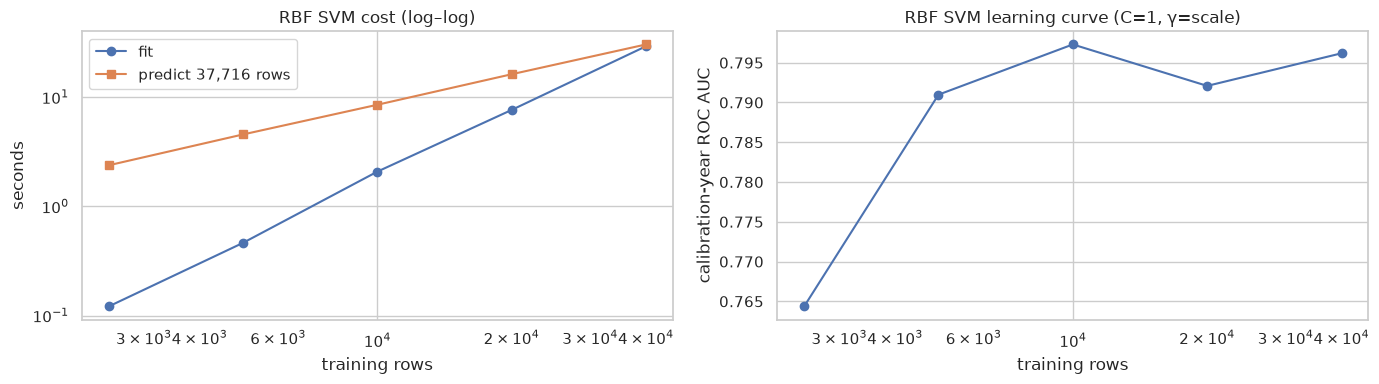

fit time grows like n^1.99; extrapolated fit on 377k rows ≈ 0.7 h (plus prediction)


,n_train,fit_s,predict_cal_s,n_support,cal_roc_auc
0,2500,0.1210,2.3737,1191,0.7644
1,5000,0.4626,4.5490,2260,0.7910
2,10000,2.0773,8.5076,4268,0.7973
3,20000,7.6328,16.1924,7929,0.7921
4,40000,29.2211,30.3514,14634,0.7962


In [9]:
def make_svc(kernel, **kw):
    return Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                     ("svm", SVC(kernel=kernel, cache_size=1500, max_iter=1_000_000, random_state=RNG, **kw))])

def make_rbf(**kw):
    return make_svc("rbf", **kw)

sizes = [2_500, 5_000, 10_000, 20_000, 40_000]
curve = []
for n in sizes:
    idx, _ = train_test_split(np.arange(len(X_fit)), train_size=n, stratify=y_fit, random_state=RNG)
    m = make_rbf(C=1.0, gamma="scale")
    t0 = time.time(); m.fit(X_fit.iloc[idx], y_fit[idx]); t_fit = time.time() - t0
    t0 = time.time(); d = m.decision_function(X_cal); t_pred = time.time() - t0
    curve.append({"n_train": n, "fit_s": t_fit, "predict_cal_s": t_pred, "n_support": int(m[-1].n_support_.sum()), "cal_roc_auc": roc_auc_score(y_cal, d)})
curve = pd.DataFrame(curve)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(curve.n_train, curve.fit_s, "o-", label="fit"); axes[0].plot(curve.n_train, curve.predict_cal_s, "s-", label=f"predict {len(X_cal):,} rows")
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_xlabel("training rows"); axes[0].set_ylabel("seconds"); axes[0].legend()
axes[0].set_title("RBF SVM cost (log–log)")
axes[1].plot(curve.n_train, curve.cal_roc_auc, "o-"); axes[1].set_xscale("log")
axes[1].set_xlabel("training rows"); axes[1].set_ylabel("calibration-year ROC AUC"); axes[1].set_title("RBF SVM learning curve (C=1, γ=scale)")
plt.tight_layout(); plt.show()
slope = np.polyfit(np.log(curve.n_train), np.log(curve.fit_s), 1)[0]
print(f"fit time grows like n^{slope:.2f}; extrapolated fit on 377k rows ≈ {curve.fit_s.iloc[-1] * (377_097 / 40_000) ** slope / 3600:.1f} h (plus prediction)")
curve

**What this shows.** The number of support vectors grows roughly linearly with *n*. With about a quarter of points as support vectors, the
classes overlap heavily, which is typical for a noisy future event. The learning curve shows whether more rows would still help.
If it's flattening by 40k, the subsample costs little accuracy. If it's still rising, the kernel SVMs are data-limited and their scores below are a lower bound.

### 5.1 Tuning C and γ

Same CV design as LR, on a stratified 20k-row subset of the same tuning sample (so each fit sees about 16k rows; fits take seconds instead of minutes).
`class_weight` is checked separately at the best (C, γ), since §4 showed it shifts the cutoff, not the ranking.

/workspaces/county_unemployment_project/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


100 fits in 721s; best: {'svm__C': 10.0, 'svm__gamma': 0.01}, CV ROC AUC 0.8599


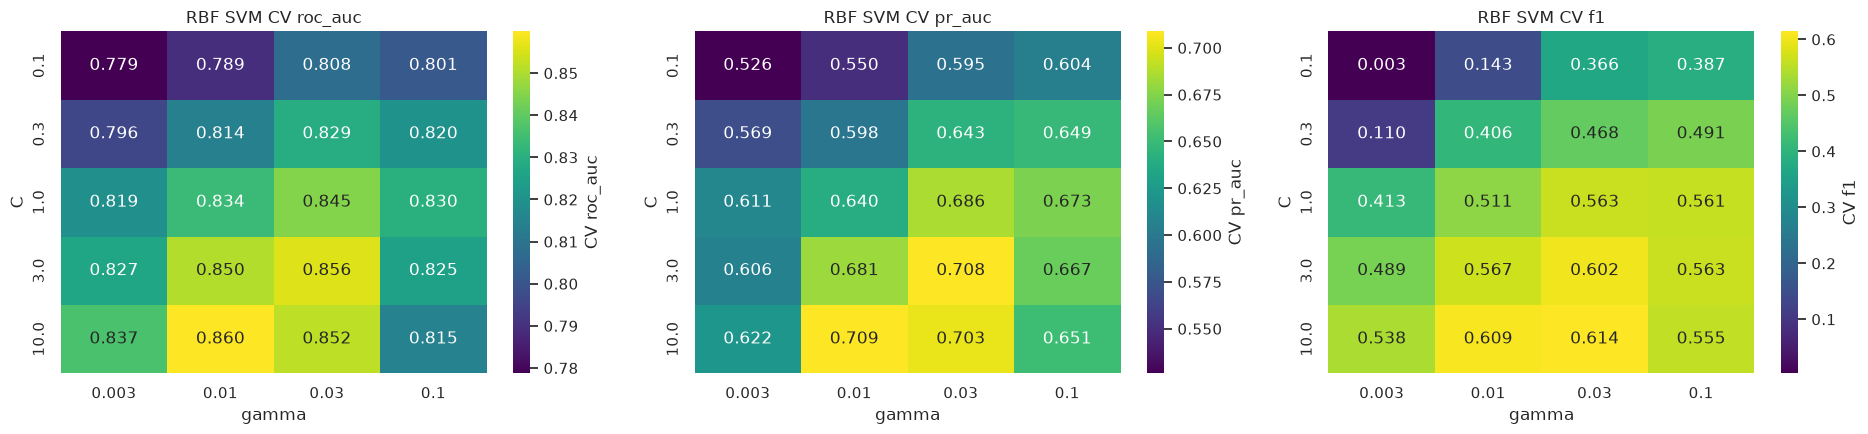

In [10]:
tune_rbf_idx, _ = train_test_split(np.arange(len(X_tune)), train_size=20_000, stratify=y_tune, random_state=RNG)
X_tr20, y_tr20, g_tr20 = X_tune.iloc[tune_rbf_idx], y_tune[tune_rbf_idx], groups_tune[tune_rbf_idx]
rbf_grid = {"svm__C": [0.1, 0.3, 1.0, 3.0, 10.0], "svm__gamma": [0.003, 0.01, 0.03, 0.1]}
t0 = time.time()
rbf_search = GridSearchCV(make_rbf(), rbf_grid, scoring=scoring, refit="roc_auc", cv=cv, n_jobs=-1).fit(X_tr20, y_tr20, groups=g_tr20)
print(f"{len(rbf_search.cv_results_['params']) * 5} fits in {time.time() - t0:.0f}s; best: {rbf_search.best_params_}, CV ROC AUC {rbf_search.best_score_:.4f}")

rc = pd.DataFrame(rbf_search.cv_results_)
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
for ax, m in zip(axes, ["roc_auc", "pr_auc", "f1"]):
    hm = rc.pivot_table(index="param_svm__C", columns="param_svm__gamma", values=f"mean_test_{m}")
    sns.heatmap(hm, annot=True, fmt=".3f", cmap="viridis", ax=ax, cbar_kws={"label": f"CV {m}"}); ax.set_title(f"RBF SVM CV {m}"); ax.set_xlabel("gamma"); ax.set_ylabel("C")
plt.tight_layout(); plt.show()

**Reading the heatmaps.** The classic SVM pattern is a **diagonal ridge**: small γ needs large C and vice versa, because both control
how flexible the boundary is. The bottom-right (large C, large γ) is the overfitting corner, and the top-left is underfitting (nearly constant).
If the best cell sits at small γ, the best RBF boundary is **nearly linear**, which says the curvature isn't buying much.

In [11]:
bp = rbf_search.best_params_
cw = []
for w in [None, "balanced"]:
    m = make_rbf(C=bp["svm__C"], gamma=bp["svm__gamma"], class_weight=w)
    s = pd.DataFrame(GridSearchCV(m, {"svm__C": [bp["svm__C"]]}, scoring=scoring, refit=False, cv=cv, n_jobs=-1)
                     .fit(X_tr20, y_tr20, groups=g_tr20).cv_results_)
    cw.append({"class_weight": str(w), **{k: s[f"mean_test_{k}"].iloc[0] for k in scoring}})
pd.DataFrame(cw).set_index("class_weight")

,roc_auc,pr_auc,f1,accuracy
class_weight,,,,
None,0.8599,0.7088,0.6095,0.7964
balanced,0.8692,0.7209,0.6504,0.7638


### 5.2 Final exact RBF SVM (40k rows)

Refit at the tuned (C, γ) on a stratified 40k-row sample of the SVM fit set (the largest size that stays practical; see the cost curve in §5), then
calibrate and score. We also look at three SVM-specific things: support vectors, the margin, and the hinge loss.

In [12]:
best_cw = pd.DataFrame(cw).set_index("class_weight").roc_auc.idxmax()
rbf_params = {"C": bp["svm__C"], "gamma": bp["svm__gamma"], "class_weight": None if best_cw == "None" else best_cw}
idx40, _ = train_test_split(np.arange(len(X_fit)), train_size=40_000, stratify=y_fit, random_state=RNG)
fit_calibrate_score("RBF SVM (40k rows)", make_rbf(**rbf_params), X_fit.iloc[idx40], y_fit[idx40])

svc = fitted["RBF SVM (40k rows)"]["model"][-1]
alpha = np.abs(svc.dual_coef_.ravel())
bound = svc.C * svc.class_weight_[y_fit[idx40][svc.support_]]   # per-row upper bound on α
print(f"support vectors: {svc.n_support_.sum():,} of 40,000 ({svc.n_support_.sum() / 40_000:.0%}); "
      f"per class (0, 1): {tuple(svc.n_support_)}; at their bound α = C·class_weight (inside the margin or misclassified): {np.mean(np.isclose(alpha, bound, rtol=1e-3)):.0%}")

RBF SVM (40k rows): fit 39s on 40,000 rows, threshold 0.429, test ROC AUC 0.7843
support vectors: 15,743 of 40,000 (39%); per class (0, 1): (np.int32(11598), np.int32(4145)); at their bound α = C·class_weight (inside the margin or misclassified): 97%


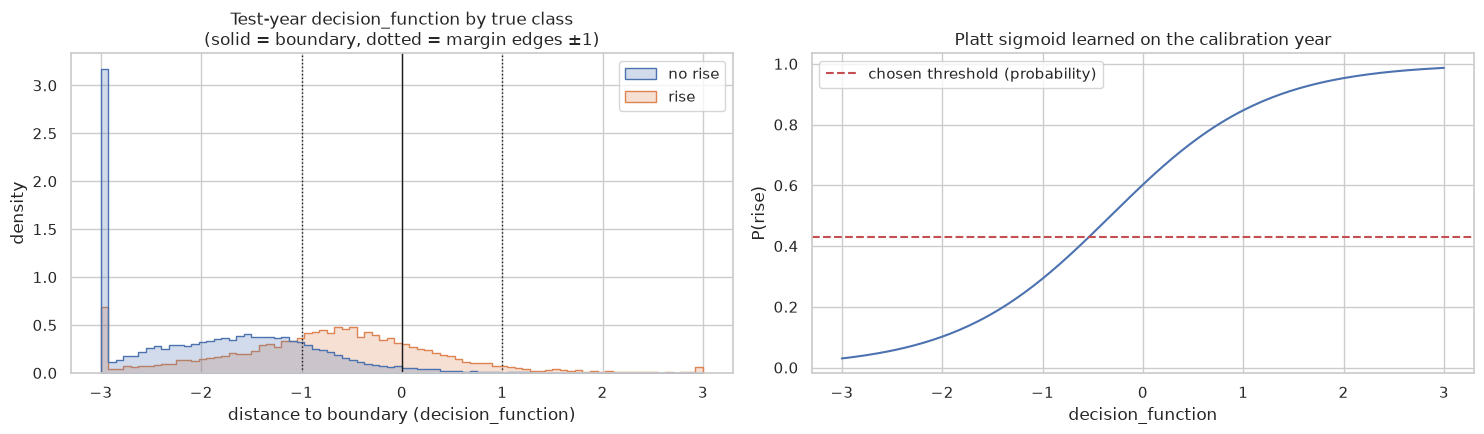

share of test rows inside the margin (|f(x)| < 1): 30%


In [13]:
dec = fitted["RBF SVM (40k rows)"]["dec_test"]
platt = fitted["RBF SVM (40k rows)"]["platt"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(x=np.clip(dec, -3, 3), hue=np.where(y_test == 1, "rise", "no rise"), bins=80, stat="density", common_norm=False, element="step", ax=axes[0])
for v, ls in [(-1, ":"), (0, "-"), (1, ":")]:
    axes[0].axvline(v, color="k", ls=ls, lw=1)
axes[0].set_title("Test-year decision_function by true class\n(solid = boundary, dotted = margin edges ±1)"); axes[0].set_xlabel("distance to boundary (decision_function)"); axes[0].set_ylabel("density")
grid = np.linspace(-3, 3, 200)
cal_curve = platt.calibrated_classifiers_[0].calibrators[0].predict(grid)
axes[1].plot(grid, cal_curve); axes[1].axhline(fitted["RBF SVM (40k rows)"]["thr"], color="#C44E52", ls="--", label="chosen threshold (probability)")
axes[1].set_xlabel("decision_function"); axes[1].set_ylabel("P(rise)"); axes[1].set_title("Platt sigmoid learned on the calibration year"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"share of test rows inside the margin (|f(x)| < 1): {np.mean(np.abs(dec) < 1):.0%}")

**Significance.**
- **Support vectors.** A large share of training rows being support vectors, nearly all at their bound α = C (C × class weight when weighted), means a lot of the data sits
  *inside the margin or on the wrong side*. The classes overlap heavily in feature space, so no boundary separates them cleanly.
  This matches LR's moderate AUC: the limit is information in the features, not model flexibility.
- **Margin.** The histogram shows how many test counties fall in the "uncertain" band between −1 and +1. For a map, those are the
  counties where any flag is a coin-flip-ish call.
- **Platt sigmoid.** It maps distance to probability. The chosen threshold corresponds to a decision value *below* 0, i.e. we flag
  some counties the raw SVM would call negative, for the same reason LR's threshold was 0.30, not 0.5.
- **Hinge loss** is reported in the results table as the SVM's own training objective, measured on test. It's comparable only between
  SVMs (LR doesn't produce a margin), so the cross-model comparison uses log loss / AUC instead.

### 5.3 Which features does the RBF SVM use?

Kernel SVMs have no coefficients. **Permutation importance** shuffles one feature at a time and measures the drop in ROC AUC, computed
on a 6k-row sample of the calibration year (not test). This is compared with the size of LR's standardized coefficients.

permutation importance in 329s


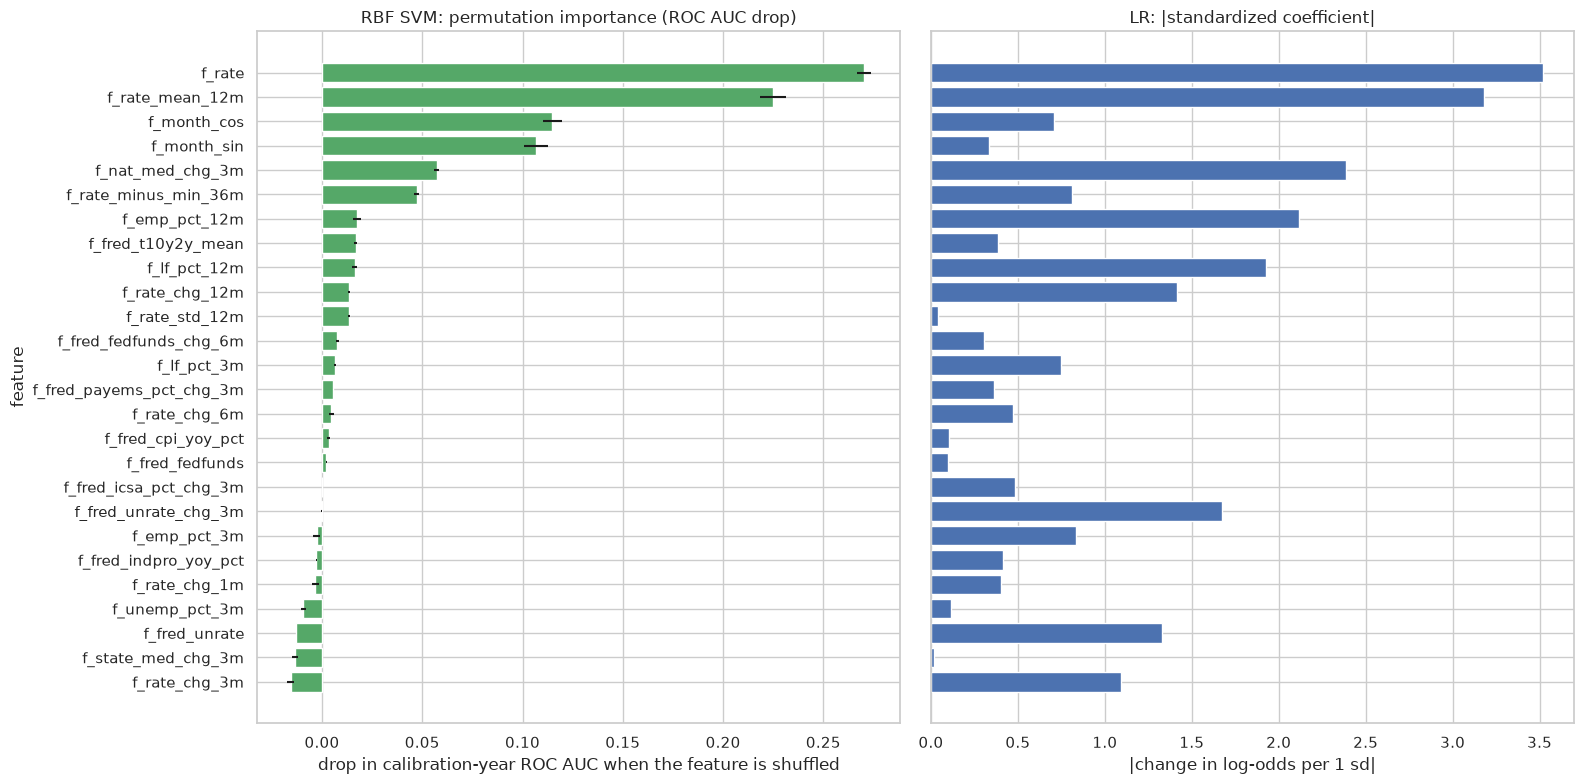

rank agreement (Spearman) between the two importance measures: 0.38


In [14]:
pi_idx, _ = train_test_split(np.arange(len(X_cal)), train_size=6_000, stratify=y_cal, random_state=RNG)
t0 = time.time()
pi = permutation_importance(fitted["RBF SVM (40k rows)"]["model"], X_cal.iloc[pi_idx], y_cal[pi_idx], scoring="roc_auc", n_repeats=3, random_state=RNG, n_jobs=-1)
print(f"permutation importance in {time.time() - t0:.0f}s")
imp = pd.DataFrame({"rbf_auc_drop": pi.importances_mean, "sd": pi.importances_std, "lr_abs_coef": lr_coef.abs()}, index=X_cols).sort_values("rbf_auc_drop")
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharey=True)
axes[0].barh(imp.index, imp.rbf_auc_drop, xerr=imp.sd, color="#55A868"); axes[0].set_title("RBF SVM: permutation importance (ROC AUC drop)")
axes[0].set_xlabel("drop in calibration-year ROC AUC when the feature is shuffled"); axes[0].set_ylabel("feature")
axes[1].barh(imp.index, imp.lr_abs_coef, color="#4C72B0"); axes[1].set_title("LR: |standardized coefficient|"); axes[1].set_xlabel("|change in log-odds per 1 sd|")
plt.tight_layout(); plt.show()
print(f"rank agreement (Spearman) between the two importance measures: {imp.rbf_auc_drop.corr(imp.lr_abs_coef, method='spearman'):.2f}")

## 6. Other kernels: polynomial and sigmoid

A kernel is a **similarity function** between two rows. Choosing one is choosing what kind of boundary the SVM can draw. RBF isn't the
only option:

| Kernel | Formula | Boundary shape | Hyperparameters |
|---|---|---|---|
| Linear (§4) | $x^\top x'$ | Flat hyperplane, same family as LR | C |
| **RBF** (§5) | $\exp(-\gamma\lVert x-x'\rVert^2)$ | Smooth, local bumps; very flexible | C, γ |
| **Polynomial** | $(\gamma\,x^\top x' + r)^d$ | All feature interactions up to degree *d* (d = 2: pairwise products like `rate × month_sin`) | C, γ, degree *d*, coef0 *r* |
| **Sigmoid** | $\tanh(\gamma\,x^\top x' + r)$ | Like a one-hidden-layer neural net; **not a valid kernel for all γ, r**, so it often behaves badly | C, γ, coef0 *r* |

The polynomial kernel is the most interpretable nonlinear option here. Degree 2 asks exactly "do *pairs* of features matter together?",
which is the county × season interaction notebook 01 suspected. `coef0 = 1` keeps the lower-order (linear) terms. With `coef0 = 0`,
a degree-2 kernel would use *only* products and drop the plain features.

Same tuning rows (the 20k subset), folds, groups, and metric (ROC AUC) as the RBF search, so the kernels compete on equal terms.

poly: 60 fits in 381s; best {'svm__C': 1.0, 'svm__coef0': 1.0, 'svm__degree': 3, 'svm__gamma': 0.04}, CV ROC AUC 0.8610


sigmoid: 45 fits in 388s; best {'svm__C': 0.1, 'svm__coef0': 0.0, 'svm__gamma': 0.001}, CV ROC AUC 0.7826


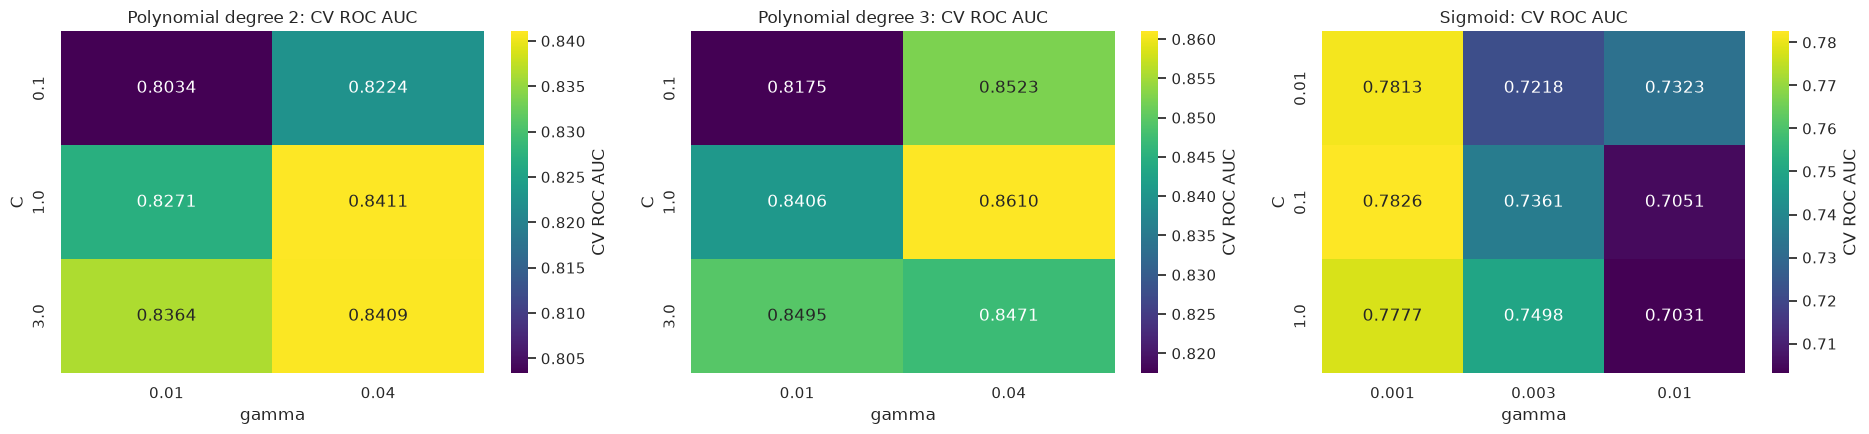

In [15]:
kernel_grids = {
    "poly": {"svm__degree": [2, 3], "svm__C": [0.1, 1.0, 3.0], "svm__gamma": [0.01, 0.04], "svm__coef0": [1.0]},
    "sigmoid": {"svm__C": [0.01, 0.1, 1.0], "svm__gamma": [0.001, 0.003, 0.01], "svm__coef0": [0.0]},
}
kernel_search = {"rbf": rbf_search}
for k, grid in kernel_grids.items():
    t0 = time.time()
    kernel_search[k] = GridSearchCV(make_svc(k), grid, scoring=scoring, refit="roc_auc", cv=cv, n_jobs=-1).fit(X_tr20, y_tr20, groups=g_tr20)
    print(f"{k}: {len(kernel_search[k].cv_results_['params']) * 5} fits in {time.time() - t0:.0f}s; best {kernel_search[k].best_params_}, CV ROC AUC {kernel_search[k].best_score_:.4f}")

pc = pd.DataFrame(kernel_search["poly"].cv_results_); sc_ = pd.DataFrame(kernel_search["sigmoid"].cv_results_)
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
for ax, d in zip(axes[:2], [2, 3]):
    hm = pc[pc.param_svm__degree == d].pivot_table(index="param_svm__C", columns="param_svm__gamma", values="mean_test_roc_auc")
    sns.heatmap(hm, annot=True, fmt=".4f", cmap="viridis", ax=ax, cbar_kws={"label": "CV ROC AUC"}); ax.set_title(f"Polynomial degree {d}: CV ROC AUC"); ax.set_xlabel("gamma"); ax.set_ylabel("C")
sns.heatmap(sc_.pivot_table(index="param_svm__C", columns="param_svm__gamma", values="mean_test_roc_auc"), annot=True, fmt=".4f", cmap="viridis", ax=axes[2], cbar_kws={"label": "CV ROC AUC"})
axes[2].set_title("Sigmoid: CV ROC AUC"); axes[2].set_xlabel("gamma"); axes[2].set_ylabel("C")
plt.tight_layout(); plt.show()

**Reading the heatmaps.** Compare the best cell of each panel with the RBF heatmap in §5.1 and the linear SVM's CV AUC in §4.
If degree 2 ≈ degree 3 ≈ RBF ≈ linear, the extra flexibility isn't finding interactions the linear model misses. The sigmoid kernel is
expected to be weakest and the most sensitive to γ: large γ saturates tanh, so every pair of rows looks either "identical" or "opposite".

Now refit each tuned kernel on the **same 40k rows** used for the RBF SVM, then calibrate and score:

Polynomial SVM (40k rows): fit 43s on 40,000 rows, threshold 0.183, test ROC AUC 0.7739


Sigmoid SVM (40k rows): fit 50s on 40,000 rows, threshold 0.292, test ROC AUC 0.7250


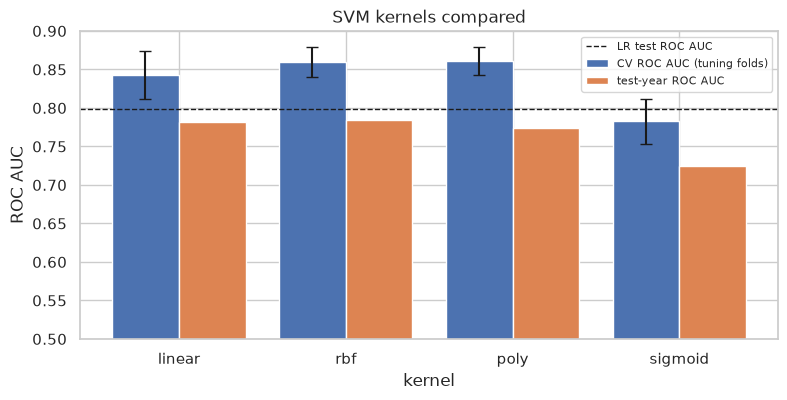

,model,best_params,cv_roc_auc,cv_sd,test_roc_auc,test_pr_auc,test_log_loss,n_support,train_rows
kernel,,,,,,,,,
linear,Linear SVM,"{'C': 10.0, 'class_weight': 'balanced', 'loss'...",0.8430,0.0316,0.7824,0.6157,0.5001,NaN,329952
rbf,RBF SVM (40k rows),"{'C': 10.0, 'gamma': 0.01}",0.8599,0.0195,0.7843,0.6192,0.5157,15743.0000,40000
poly,Polynomial SVM (40k rows),"{'C': 1.0, 'coef0': 1.0, 'degree': 3, 'gamma':...",0.8610,0.0181,0.7739,0.6083,0.5112,13256.0000,40000
sigmoid,Sigmoid SVM (40k rows),"{'C': 0.1, 'coef0': 0.0, 'gamma': 0.001}",0.7826,0.0288,0.7250,0.5079,0.5458,20597.0000,40000


In [16]:
KNAME = {"rbf": "RBF", "poly": "Polynomial", "sigmoid": "Sigmoid"}
kernel_params = {"rbf": rbf_params}
for k in ["poly", "sigmoid"]:
    kernel_params[k] = {kk.replace("svm__", ""): v for kk, v in kernel_search[k].best_params_.items()}
    fit_calibrate_score(f"{KNAME[k]} SVM (40k rows)", make_svc(k, **kernel_params[k]), X_fit.iloc[idx40], y_fit[idx40])

kern = []
for k in ["linear", "rbf", "poly", "sigmoid"]:
    name = "Linear SVM" if k == "linear" else f"{KNAME[k]} SVM (40k rows)"
    srch = lin_search if k == "linear" else kernel_search[k]
    m = fitted[name]["model"][-1]
    kern.append({"kernel": k, "model": name, "best_params": {kk.replace("svm__", ""): v for kk, v in srch.best_params_.items()},
                 "cv_roc_auc": srch.best_score_, "cv_sd": srch.cv_results_["std_test_roc_auc"][srch.best_index_],
                 "test_roc_auc": roc_auc_score(y_test, probs[name]), "test_pr_auc": average_precision_score(y_test, probs[name]),
                 "test_log_loss": log_loss(y_test, probs[name]),
                 "n_support": int(m.n_support_.sum()) if hasattr(m, "n_support_") else np.nan,
                 "train_rows": 40_000 if k != "linear" else len(X_fit)})
kern = pd.DataFrame(kern).set_index("kernel")

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(kern))
ax.bar(x - 0.2, kern.cv_roc_auc, 0.4, yerr=kern.cv_sd, capsize=4, label="CV ROC AUC (tuning folds)")
ax.bar(x + 0.2, kern.test_roc_auc, 0.4, label="test-year ROC AUC")
ax.axhline(roc_auc_score(y_test, probs["LR (EN ρ=0.25, C=0.1)"]), color="k", ls="--", lw=1, label="LR test ROC AUC")
ax.set_xticks(x); ax.set_xticklabels(kern.index); ax.set_ylim(0.5, 0.9); ax.legend(fontsize=8); ax.set_title("SVM kernels compared"); ax.set_xlabel("kernel"); ax.set_ylabel("ROC AUC")
plt.show()
kern

**Significance.** This table is the kernel verdict. Look for three things:
1. **Test vs. CV gap per kernel.** A flexible kernel with a big gap is fitting patterns of the training years that don't carry forward.
2. **Number of support vectors.** Fewer support vectors at similar AUC means a simpler, cheaper-to-predict boundary.
3. **Against the dashed LR line.** A kernel has to clear it by more than the bootstrap noise in §8.1 to justify its cost.

The best kernel by **CV** ROC AUC (not test, to avoid choosing on the test set) is the one carried into §7.

In [17]:
best_kernel = max(["rbf", "poly", "sigmoid"], key=lambda k: kernel_search[k].best_score_)
LESSON_SVM = f"{KNAME[best_kernel]} SVM (40k) + seasonal feats, no COVID"
print(f"best kernel by CV ROC AUC: {best_kernel} {kernel_params[best_kernel]}")

best kernel by CV ROC AUC: poly {'C': 1.0, 'coef0': 1.0, 'degree': 3, 'gamma': 0.04}


## 7. Applying LR's lessons: county seasonality and dropping COVID

Notebook 01's two clearest leads were (1) the seasonal-naive rule beats every model, so the features lack **county-specific
seasonality**, and (2) training without 2020–21 helps. Here both are applied to LR, the linear SVM, and the best kernel SVM (chosen by CV in §6):
- **Two new features (computed in this notebook, not in the mart):** `x_seas_chg_1y = rate(t−9) − rate(t−12)` and
  `x_seas_chg_2y = rate(t−21) − rate(t−24)`, the county's own change over the same window one and two years ago. Both look only backward.
- **Training rows from 2020–21 are dropped.** The calibration year and test year are unchanged.

Hyperparameters stay at the values tuned above (re-tuning per variant would cost hours for little expected gain), so this isolates
the effect of the data change.

In [18]:
df_feats = lab[["county_month_id"]].assign(x_seas_chg_1y=lab.rate_tm9 - lab.rate_tm12, x_seas_chg_2y=lab.rate_tm21 - lab.rate_tm24).set_index("county_month_id")
X2_cols = X_cols + ["x_seas_chg_1y", "x_seas_chg_2y"]
def add_feats(part):
    return part.join(df_feats, on="county_month_id")
train2, test2, fit2, cal2 = (add_feats(p) for p in (train, test, fit, cal))
keep_tr = ~train2.month.dt.year.isin([2020, 2021]); keep_fit = ~fit2.month.dt.year.isin([2020, 2021])
print(f"null rate of new features (train): {train2[['x_seas_chg_1y', 'x_seas_chg_2y']].isna().mean().round(3).to_dict()}")
print(f"univariate test ROC AUC of x_seas_chg_1y: {roc_auc_score(y_test, test2.x_seas_chg_1y.fillna(0)):.3f}")

X_cal_orig, X_test_orig = X_cal, X_test
X_cal, X_test = cal2[X2_cols], test2[X2_cols]   # fit_calibrate_score reads these globals

t0 = time.time(); lr2 = make_lr().fit(train2.loc[keep_tr, X2_cols], train2.y.values[keep_tr]); t_lr2 = time.time() - t0
oof2 = cross_val_predict(make_lr(), add_feats(tune)[X2_cols], y_tune, cv=cv, groups=groups_tune, method="predict_proba", n_jobs=-1)[:, 1]
THR_LR2, _ = f1_threshold(y_tune, oof2)
probs["LR + seasonal feats, no COVID"] = lr2.predict_proba(X_test)[:, 1]
rows.append(evaluate("LR + seasonal feats, no COVID", y_test, probs["LR + seasonal feats, no COVID"], thr=THR_LR2, fit_s=t_lr2))
print(f"LR + seasonal, no COVID: test ROC AUC {roc_auc_score(y_test, probs['LR + seasonal feats, no COVID']):.4f}")

fit_calibrate_score("Linear SVM + seasonal feats, no COVID",
                    make_linsvm(**{k.replace("svm__", ""): v for k, v in lin_search.best_params_.items()}),
                    fit2.loc[keep_fit, X2_cols], fit2.y.values[keep_fit])
fit2_nc = fit2[keep_fit]
idx40b, _ = train_test_split(np.arange(len(fit2_nc)), train_size=40_000, stratify=fit2_nc.y, random_state=RNG)
fit_calibrate_score(LESSON_SVM, make_svc(best_kernel, **kernel_params[best_kernel]), fit2_nc[X2_cols].iloc[idx40b], fit2_nc.y.values[idx40b])
X_cal, X_test = X_cal_orig, X_test_orig

null rate of new features (train): {'x_seas_chg_1y': 0.1, 'x_seas_chg_2y': 0.2}
univariate test ROC AUC of x_seas_chg_1y: 0.856


LR + seasonal, no COVID: test ROC AUC 0.8613


Linear SVM + seasonal feats, no COVID: fit 474s on 254,520 rows, threshold 0.352, test ROC AUC 0.8556


Polynomial SVM (40k) + seasonal feats, no COVID: fit 36s on 40,000 rows, threshold 0.295, test ROC AUC 0.8267


## 8. Final comparison: SVM vs. logistic regression on the test year

All models are scored on the **same 37,716 test rows**. Thresholds were chosen on training-period data only (LR: out-of-fold CV;
SVMs: calibration year). How to read the columns:
- **log_loss / brier** (lower is better): quality of probabilities. For SVMs, these are the Platt-calibrated probabilities.
- **roc_auc / pr_auc** (higher is better): ranking quality, threshold-free. **The fairest single comparison.**
- **hinge** (lower is better): SVM objective on test, SVM rows only.
- **accuracy / precision / recall / F1**: at each model's own pre-chosen threshold.
- **fit_seconds**: training time (not counting tuning). A real cost when retraining every 6 months.

In [19]:
results = pd.DataFrame(rows).set_index("model")
results.style.format("{:.4f}", na_rep="–").format("{:.0f}", subset=["fit_seconds"], na_rep="–") \
    .highlight_min(subset=["log_loss", "brier"], color="#d4edda").highlight_max(subset=["roc_auc", "pr_auc", "f1", "accuracy"], color="#d4edda")

,threshold,log_loss,brier,roc_auc,pr_auc,hinge,accuracy,precision,recall,f1,fit_seconds
model,,,,,,,,,,,
Dummy (prior),0.5000,0.6013,0.2055,0.5000,0.2884,–,0.7116,0.0000,0.0000,0.0000,–
Seasonal-naive rule,–,–,–,–,–,–,0.7940,0.6247,0.7156,0.6671,–
"LR (EN ρ=0.25, C=0.1)",0.2969,0.4977,0.1631,0.7986,0.6432,–,0.7660,0.5958,0.5862,0.5909,58
Linear SVM,0.3723,0.5001,0.1611,0.7824,0.6157,0.5725,0.7502,0.5665,0.5699,0.5682,704
RBF SVM (40k rows),0.4288,0.5157,0.1616,0.7843,0.6192,0.5982,0.7783,0.6858,0.4266,0.5260,39
Polynomial SVM (40k rows),0.1829,0.5112,0.1661,0.7739,0.6083,0.8294,0.6543,0.4428,0.7690,0.5620,43
Sigmoid SVM (40k rows),0.2920,0.5458,0.1810,0.7250,0.5079,0.5822,0.6969,0.4786,0.5690,0.5199,50
"LR + seasonal feats, no COVID",0.2606,0.4216,0.1300,0.8613,0.7319,–,0.7866,0.6016,0.7704,0.6756,36
"Linear SVM + seasonal feats, no COVID",0.3524,0.4438,0.1354,0.8556,0.7179,0.4655,0.8114,0.6903,0.6275,0.6574,474


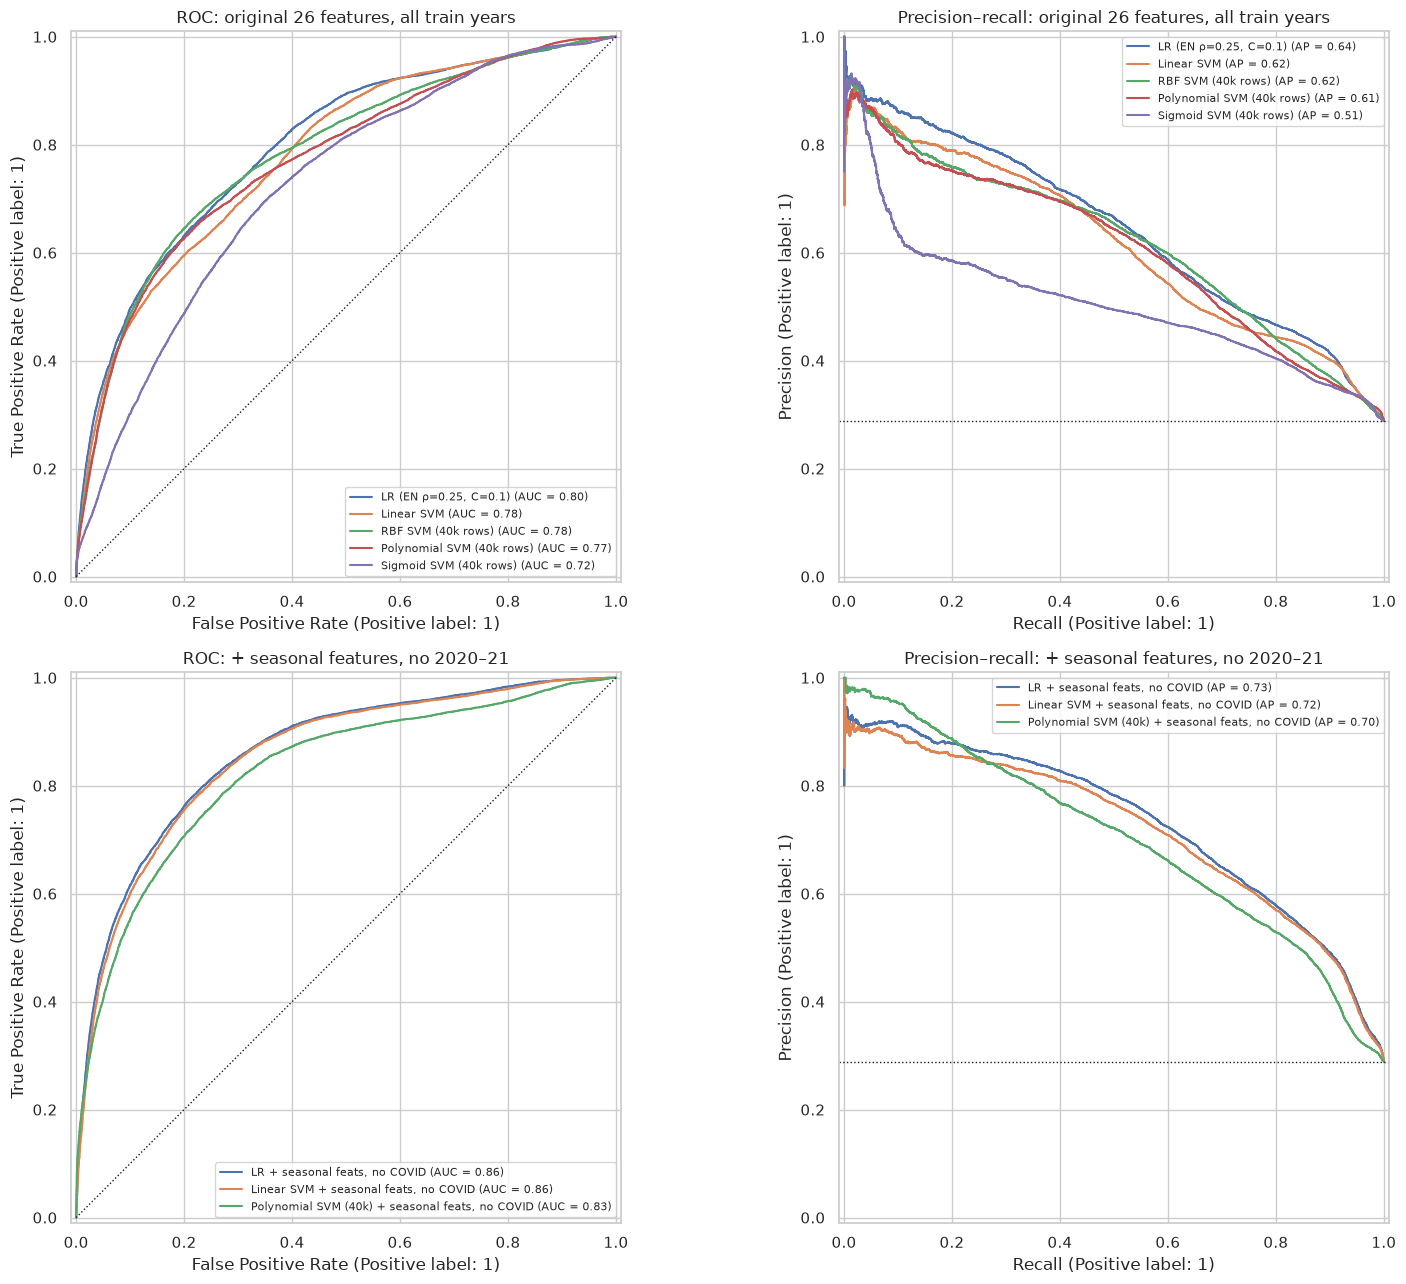

In [20]:
base = ["LR (EN ρ=0.25, C=0.1)", "Linear SVM", "RBF SVM (40k rows)", "Polynomial SVM (40k rows)", "Sigmoid SVM (40k rows)"]
lessons = ["LR + seasonal feats, no COVID", "Linear SVM + seasonal feats, no COVID", LESSON_SVM]
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
for row_axes, names, title in [(axes[0], base, "original 26 features, all train years"), (axes[1], lessons, "+ seasonal features, no 2020–21")]:
    for name in names:
        RocCurveDisplay.from_predictions(y_test, probs[name], name=name, ax=row_axes[0])
        PrecisionRecallDisplay.from_predictions(y_test, probs[name], name=name, ax=row_axes[1])
    row_axes[0].plot([0, 1], [0, 1], "k:", lw=1); row_axes[0].set_title(f"ROC: {title}")
    row_axes[1].axhline(y_test.mean(), color="k", ls=":", lw=1); row_axes[1].set_title(f"Precision–recall: {title}")
    for ax in row_axes: ax.legend(fontsize=8, loc="lower right" if ax is row_axes[0] else "upper right")
plt.tight_layout(); plt.show()

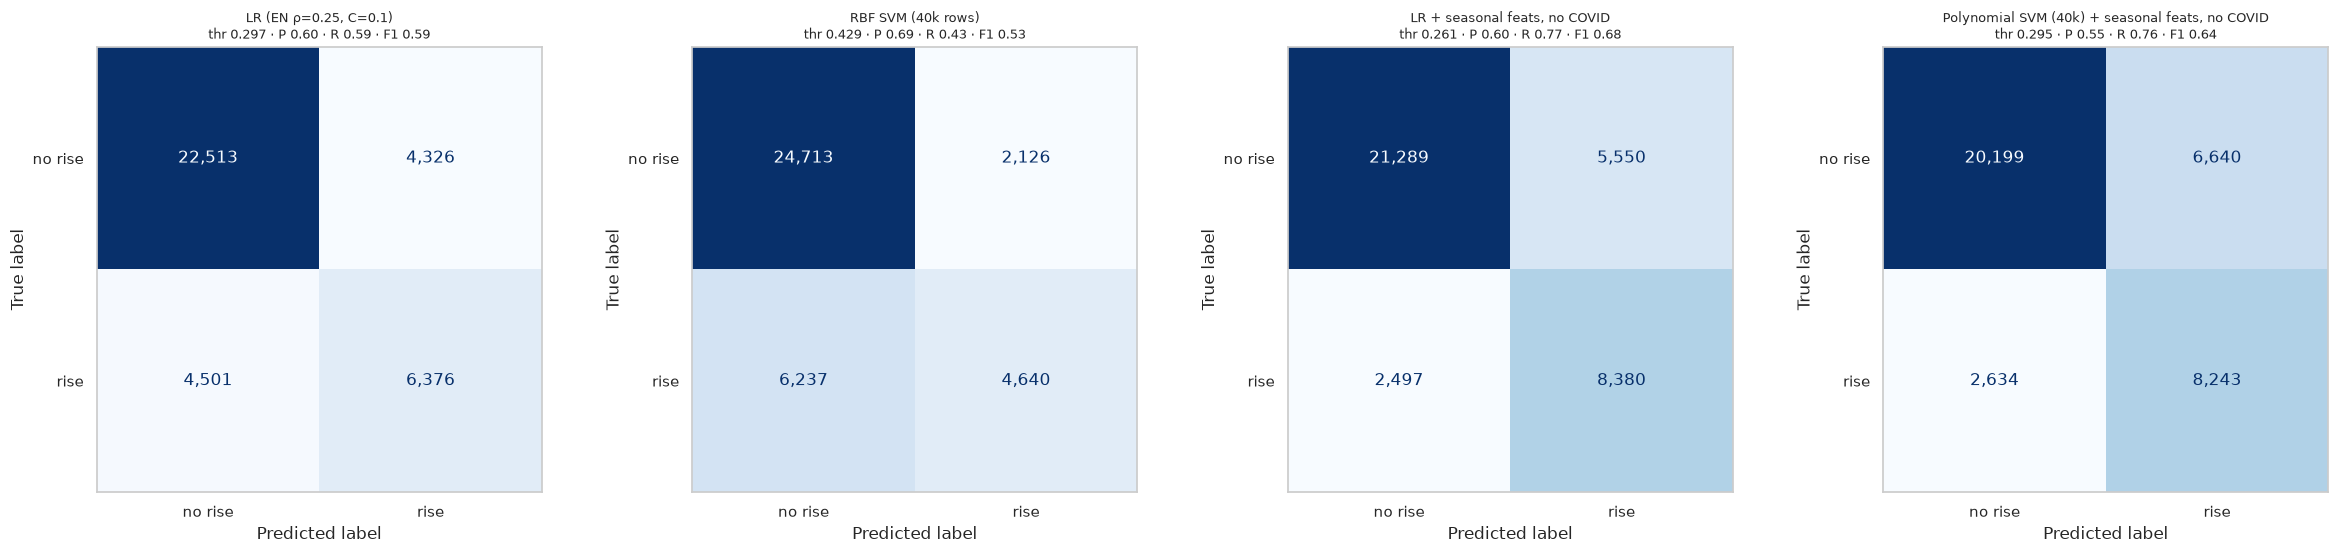

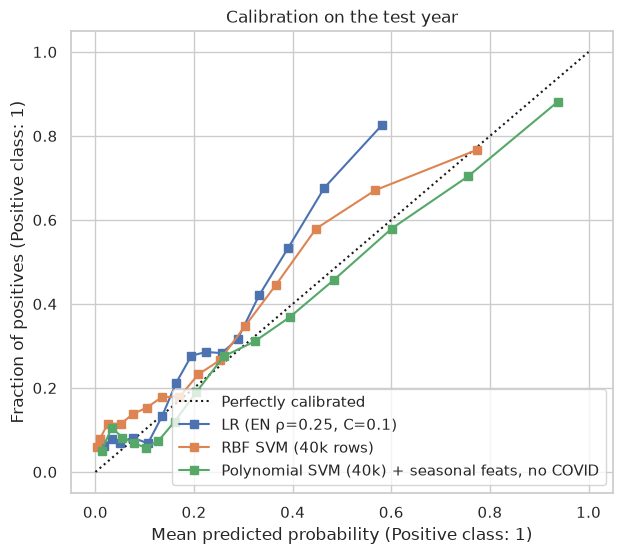

In [21]:
best_svm = results.loc[[i for i in results.index if "SVM" in i and "seasonal" not in i]].roc_auc.idxmax()
pairs = [("LR (EN ρ=0.25, C=0.1)", THR_LR), (best_svm, fitted[best_svm]["thr"]),
         ("LR + seasonal feats, no COVID", THR_LR2), (LESSON_SVM, fitted[LESSON_SVM]["thr"])]
fig, axes = plt.subplots(1, 4, figsize=(24, 5.5))
for ax, (name, t) in zip(axes, pairs):
    yhat = (probs[name] >= t).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, yhat), display_labels=["no rise", "rise"]).plot(ax=ax, cmap="Blues", values_format=",", colorbar=False)
    ax.set_title(f"{name}\nthr {t:.3f} · P {precision_score(y_test, yhat):.2f} · R {recall_score(y_test, yhat):.2f} · F1 {f1_score(y_test, yhat):.2f}", fontsize=9)
    ax.grid(False)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
for name in ["LR (EN ρ=0.25, C=0.1)", best_svm, LESSON_SVM]:
    CalibrationDisplay.from_predictions(y_test, probs[name], n_bins=15, strategy="quantile", name=name, ax=ax)
ax.set_title("Calibration on the test year"); plt.show()

### 8.1 Is the difference real? A county-clustered bootstrap

Test rows aren't independent (each county appears 12 times), so a naive bootstrap would understate uncertainty. We resample **whole
counties** with replacement 300 times and recompute the ROC AUC difference (model − LR) each time. If the 95% interval includes 0,
the models are indistinguishable on this test year.

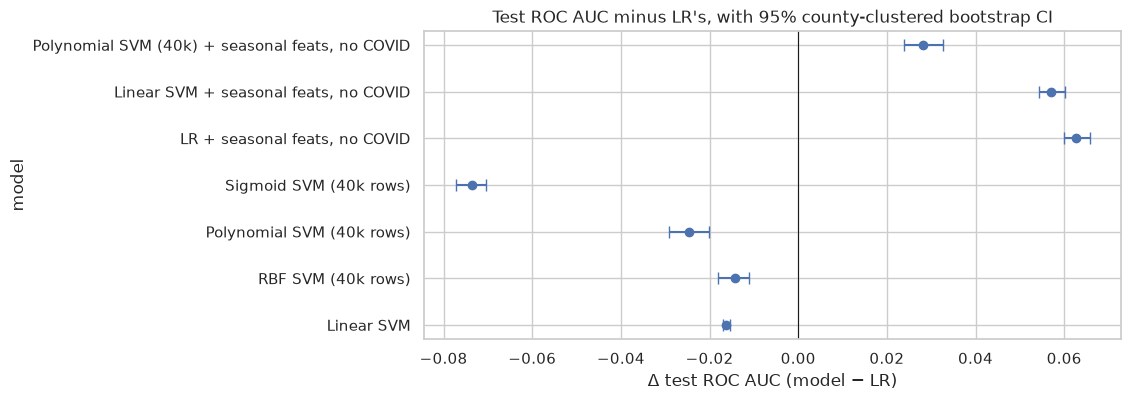

,auc_diff_vs_LR,ci_low,ci_high,significant
Linear SVM,-0.0162,-0.0171,-0.0153,True
RBF SVM (40k rows),-0.0143,-0.0181,-0.0111,True
Polynomial SVM (40k rows),-0.0247,-0.0291,-0.0202,True
Sigmoid SVM (40k rows),-0.0736,-0.0773,-0.0704,True
"LR + seasonal feats, no COVID",0.0627,0.0600,0.0658,True
"Linear SVM + seasonal feats, no COVID",0.0570,0.0543,0.0602,True
"Polynomial SVM (40k) + seasonal feats, no COVID",0.0281,0.0239,0.0326,True


In [22]:
rng = np.random.default_rng(RNG)
county_codes, uniq = pd.factorize(test.county_fips)
rows_by_county = [np.flatnonzero(county_codes == k) for k in range(len(uniq))]
ref = probs["LR (EN ρ=0.25, C=0.1)"]
others = [n for n in probs if n not in ("LR (EN ρ=0.25, C=0.1)",)]
diffs = {n: [] for n in others}
for _ in range(300):
    ix = np.concatenate([rows_by_county[k] for k in rng.integers(0, len(uniq), len(uniq))])
    a = roc_auc_score(y_test[ix], ref[ix])
    for n in others:
        diffs[n].append(roc_auc_score(y_test[ix], probs[n][ix]) - a)
boot = pd.DataFrame({n: {"auc_diff_vs_LR": roc_auc_score(y_test, probs[n]) - roc_auc_score(y_test, ref),
                         "ci_low": np.percentile(d, 2.5), "ci_high": np.percentile(d, 97.5)} for n, d in diffs.items()}).T
boot["significant"] = (boot.ci_low > 0) | (boot.ci_high < 0)
plt.figure(figsize=(9, 4))
plt.errorbar(boot.auc_diff_vs_LR, range(len(boot)), xerr=[boot.auc_diff_vs_LR - boot.ci_low, boot.ci_high - boot.auc_diff_vs_LR], fmt="o", capsize=4)
plt.yticks(range(len(boot)), boot.index); plt.axvline(0, color="k", lw=0.8)
plt.title("Test ROC AUC minus LR's, with 95% county-clustered bootstrap CI"); plt.xlabel("Δ test ROC AUC (model − LR)"); plt.ylabel("model"); plt.show()
boot

In [23]:
r = results
print(f"Test year {test.month.min():%Y-%m} to {test.month.max():%Y-%m}; positive rate {y_test.mean():.3f}\n")
print(r[["log_loss", "roc_auc", "pr_auc", "f1", "fit_seconds"]].round(4).to_string())
print(f"\nbest SVM on the original features: {best_svm}")
print(f"linear SVM: {lin_search.best_params_}")
for k in ["rbf", "poly", "sigmoid"]:
    print(f"{k}: {kernel_params[k]}  (CV ROC AUC {kernel_search[k].best_score_:.4f})")

Test year 2025-04 to 2026-05; positive rate 0.288

                                                 log_loss  roc_auc  pr_auc     f1  fit_seconds
model                                                                                         
Dummy (prior)                                      0.6013   0.5000  0.2884 0.0000          NaN
Seasonal-naive rule                                   NaN      NaN     NaN 0.6671          NaN
LR (EN ρ=0.25, C=0.1)                              0.4977   0.7986  0.6432 0.5909      57.8798
Linear SVM                                         0.5001   0.7824  0.6157 0.5682     703.5431
RBF SVM (40k rows)                                 0.5157   0.7843  0.6192 0.5260      39.3496
Polynomial SVM (40k rows)                          0.5112   0.7739  0.6083 0.5620      42.9716
Sigmoid SVM (40k rows)                             0.5458   0.7250  0.5079 0.5199      49.7422
LR + seasonal feats, no COVID                      0.4216   0.8613  0.7319 0.6756      35.9512

## 9. Conclusions

_Numbers from the run on 2026-10-24 (test year 2025-04 to 2026-05, positive rate 0.288). They will shift slightly as the data updates._

**1. On the original 26 features, no SVM beats logistic regression.** Test ROC AUC: LR **0.799**; RBF 0.784; linear SVM 0.782;
polynomial 0.774; sigmoid 0.725. The county-clustered bootstrap puts *every* SVM significantly **below** LR (e.g. RBF −0.014,
95% CI −0.018 to −0.011). LR also has the best log loss (0.498 vs 0.500–0.546).

**2. Kernels win in CV and lose on the future.** In CV the nonlinear kernels looked better than linear models
(RBF 0.860 with balanced weights 0.869, poly 0.861 vs. linear SVM 0.843 / LR 0.842). On the test year they're worse. CV folds mix years,
so the extra flexibility learns patterns of *past regimes* (which counties rose, in which macro conditions) that don't carry
forward. This is the same optimism notebook 01 found, and it's larger for flexible models.

**3. What the SVM-specific diagnostics say.** The exact RBF SVM keeps **39% of its training rows as support vectors** (15,743 of 40k), and
**97% of those sit at their bound** (inside the margin or misclassified). **30% of test rows fall inside the margin** (|f(x)| < 1).
The classes overlap heavily: the limit is the *information in the features*, not the shape of the boundary. The learning curve
flattens after about 10k rows (calibration-year AUC 0.797 at 10k vs. 0.796 at 40k), so subsampling didn't hold the kernels back.

**4. Kernel ranking.** Polynomial (degree 3) ≈ RBF > linear >> sigmoid in CV; RBF ≈ linear > polynomial >> sigmoid on test.
The sigmoid kernel is clearly worst, as expected (it isn't a proper kernel for most γ, r). The degree-3 polynomial overfits the
most (CV 0.861 → test 0.774).

**5. LR's lessons matter far more than the model choice.** Adding the county's own same-window change from 1 and 2 years ago and
dropping 2020–21 from training lifts **every** model by about 0.05–0.07 AUC:

| Model | Test ROC AUC (original → with lessons) | Test F1 |
|---|---|---|
| LR | 0.799 → **0.861** | 0.59 → **0.68** |
| Linear SVM | 0.782 → 0.856 | 0.57 → 0.66 |
| Polynomial SVM | 0.774 → 0.827 | 0.56 → 0.64 |

**LR + seasonal features is the first model that beats the seasonal-naive rule on F1** (0.676 vs 0.667), with ROC AUC 0.861
and the best log loss of anything tried (0.422).

**6. Cost.** LR fits all 377k rows in about 40–80 s. The linear SVM took 10–15 min (liblinear's hinge solver at C = 10 is slow). Kernel SVMs
can only use about 40k rows, and they need a separate calibration year to produce probabilities. For retraining every 6 months, LR is
cheaper, simpler, and more accurate here.

**Verdict.** Keep logistic regression. The next gain comes from features, not from the classifier: add the two seasonal-change
features to the `county_month` mart and decide how to handle 2020–21. If you try another model family, gradient-boosted
trees are the better next candidate than SVMs, but judge them on the out-of-time test year, since CV flatters flexible models.

**Caveats.** One test year, one regime. Kernel SVMs were tuned on 20k rows and fit on 40k, so they saw less data than LR (the learning
curve suggests this cost little). SVM probabilities come from Platt scaling on 2024, so their log loss partly reflects how similar
2024 is to the test year. The seasonal features were computed in this notebook, not the mart. Nothing was saved. Notebook 03 (`03_final_model.ipynb`) re-checks the finalists and declares the best model: LR trained without 2020–21.